In [1]:
import io
import requests
import numpy as np
import pandas as pd
from collections import deque
from scipy.stats import poisson
from scipy.optimize import minimize
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import log_loss

# ==========================================
# 1. DESCARGA Y LIMPIEZA DE DATOS LIGA MX
# ==========================================
URL = "https://www.football-data.co.uk/new/MEX.csv"
resp = requests.get(URL, headers={"User-Agent": "Mozilla/5.0"}, timeout=30)
resp.raise_for_status()

df = pd.read_csv(io.StringIO(resp.text))
home_col = "Home" if "Home" in df.columns else "HomeTeam"
away_col = "Away" if "Away" in df.columns else "AwayTeam"

df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")
df["HG"] = pd.to_numeric(df["HG"], errors="coerce")
df["AG"] = pd.to_numeric(df["AG"], errors="coerce")
df = df.dropna(subset=["Date", home_col, away_col, "HG", "AG"]).sort_values("Date").reset_index(drop=True)
df["y"] = np.where(df["HG"] > df["AG"], 0, np.where(df["HG"] == df["AG"], 1, 2))

ALTITUD_KEYWORDS = {
    "toluca": 2660, "pachuca": 2420, "america": 2240, "cruz azul": 2240,
    "pumas": 2240, "unam": 2240, "atlante": 2240, "puebla": 2135, "leon": 1815,
    "queretaro": 1820, "san luis": 1860, "necaxa": 1885, "guadalajara": 1566,
    "chivas": 1566, "atlas": 1566, "morelia": 1920, "juarez": 1138,
    "santos": 1120, "monterrey": 540, "tigres": 540, "uanl": 540,
    "tijuana": 20, "mazatlan": 10, "veracruz": 10
}

def get_altitude(team_name: str) -> float:
    name = str(team_name).lower()
    for k, alt in ALTITUD_KEYWORDS.items():
        if k in name:
            return float(alt)
    return 1200.0

def dixon_coles_probs(lam_h: float, lam_a: float, rho: float = -0.08, max_goals: int = 8):
    h_probs = poisson.pmf(np.arange(max_goals), lam_h)
    a_probs = poisson.pmf(np.arange(max_goals), lam_a)
    mat = np.outer(h_probs, a_probs)
    mat[0, 0] *= max(0.0, 1.0 - lam_h * lam_a * rho)
    mat[1, 0] *= max(0.0, 1.0 + lam_a * rho)
    mat[0, 1] *= max(0.0, 1.0 + lam_h * rho)
    mat[1, 1] *= max(0.0, 1.0 - rho)
    mat /= mat.sum()
    return float(np.tril(mat, -1).sum()), float(np.trace(mat)), float(np.triu(mat, 1).sum()), mat

def brier_multiclass(y_true, probs):
    y_oh = np.eye(3)[y_true]
    return float(np.mean(np.sum((y_oh - probs) ** 2, axis=1)))

def safe_mean(dq, default):
    return float(np.mean(dq)) if len(dq) > 0 else float(default)

WARMUP = 150
TEST_SIZE = 300

# ==========================================
# 2. MOTOR v1 (ORIGINAL CON SESGO DE LOCALÍA)
# ==========================================
def build_v1(df_in):
    elo, att, def_w, last_date, pts_hist, gd_hist = {}, {}, {}, {}, {}, {}
    BASE_HG, BASE_AG, LR_VEC = 1.48, 1.12, 0.08
    rows = []

    for _, row in df_in.iterrows():
        h, a, dt, hg, ag = row[home_col], row[away_col], row["Date"], row["HG"], row["AG"]
        for t in (h, a):
            if t not in elo:
                elo[t], att[t], def_w[t], last_date[t] = 1500.0, 1.0, 1.0, None
                pts_hist[t], gd_hist[t] = deque(maxlen=5), deque(maxlen=5)

        alt_diff = (get_altitude(h) - get_altitude(a)) / 1000.0
        rest_h = min(21, (dt - last_date[h]).days) if last_date[h] is not None else 14
        rest_a = min(21, (dt - last_date[a]).days) if last_date[a] is not None else 14
        elo_diff = (elo[h] + 60.0 - elo[a]) / 100.0

        lam_h = np.clip(BASE_HG * att[h] * def_w[a] * np.exp(0.05 * elo_diff + 0.02 * alt_diff), 0.35, 3.8)
        lam_a = np.clip(BASE_AG * att[a] * def_w[h] * np.exp(-0.05 * elo_diff - 0.02 * alt_diff), 0.30, 3.5)
        p_h, p_d, p_a, _ = dixon_coles_probs(lam_h, lam_a)

        rows.append({
            "p_h_dc": p_h, "p_d_dc": p_d, "p_a_dc": p_a, "lam_h": lam_h, "lam_a": lam_a,
            "elo_diff": elo_diff, "att_h": att[h], "def_h": def_w[h], "att_a": att[a], "def_a": def_w[a],
            "form_pts_diff": safe_mean(pts_hist[h], 1.3) - safe_mean(pts_hist[a], 1.3),
            "form_gd_diff": safe_mean(gd_hist[h], 0.0) - safe_mean(gd_hist[a], 0.0),
            "alt_diff": alt_diff, "rest_diff": rest_h - rest_a, "y": row["y"]
        })

        exp_h = 1.0 / (1.0 + 10.0 ** ((elo[a] - (elo[h] + 60.0)) / 400.0))
        act_h = 1.0 if hg > ag else (0.5 if hg == ag else 0.0)
        k = 22.0 * (np.log(abs(hg - ag) + 1.0) + 1.0)
        elo[h] += k * (act_h - exp_h)
        elo[a] += k * ((1.0 - act_h) - (1.0 - exp_h))

        exp_hg, exp_ag = BASE_HG * att[h] * def_w[a], BASE_AG * att[a] * def_w[h]
        att[h] = np.clip(att[h] + LR_VEC * (hg - exp_hg) / max(0.6, def_w[a]), 0.45, 2.2)
        def_w[a] = np.clip(def_w[a] + LR_VEC * (hg - exp_hg) / max(0.6, att[h]), 0.45, 2.2)
        att[a] = np.clip(att[a] + LR_VEC * (ag - exp_ag) / max(0.6, def_w[h]), 0.45, 2.2)
        def_w[h] = np.clip(def_w[h] + LR_VEC * (ag - exp_ag) / max(0.6, att[a]), 0.45, 2.2)

        last_date[h] = last_date[a] = dt
        pts_hist[h].append(3 if hg > ag else (1 if hg == ag else 0))
        pts_hist[a].append(3 if ag > hg else (1 if ag == hg else 0))
        gd_hist[h].append(hg - ag)
        gd_hist[a].append(ag - hg)

    fdf = pd.DataFrame(rows)
    fcols = [c for c in fdf.columns if c != "y"]
    tr, te = fdf.iloc[WARMUP:-TEST_SIZE], fdf.iloc[-TEST_SIZE:]
    model = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.03, max_iter=180,
                                           l2_regularization=10.0, min_samples_leaf=30, random_state=42)
    model.fit(tr[fcols], tr["y"])
    p_hyb_te = 0.55 * te[["p_h_dc", "p_d_dc", "p_a_dc"]].values + 0.45 * model.predict_proba(te[fcols])

    def predict(local, visita, rest_h=7, rest_a=7):
        el_h, el_a = elo.get(local, 1500.0), elo.get(visita, 1500.0)
        ah, dh, aa, da = att.get(local, 1.0), def_w.get(local, 1.0), att.get(visita, 1.0), def_w.get(visita, 1.0)
        alt_diff = (get_altitude(local) - get_altitude(visita)) / 1000.0
        elo_diff = (el_h + 60.0 - el_a) / 100.0
        lh = np.clip(BASE_HG * ah * da * np.exp(0.05 * elo_diff + 0.02 * alt_diff), 0.35, 3.8)
        la = np.clip(BASE_AG * aa * dh * np.exp(-0.05 * elo_diff - 0.02 * alt_diff), 0.30, 3.5)
        ph, pd_, pa, _ = dixon_coles_probs(lh, la)
        X = pd.DataFrame([{
            "p_h_dc": ph, "p_d_dc": pd_, "p_a_dc": pa, "lam_h": lh, "lam_a": la,
            "elo_diff": elo_diff, "att_h": ah, "def_h": dh, "att_a": aa, "def_a": da,
            "form_pts_diff": safe_mean(pts_hist.get(local, []), 1.3) - safe_mean(pts_hist.get(visita, []), 1.3),
            "form_gd_diff": safe_mean(gd_hist.get(local, []), 0.0) - safe_mean(gd_hist.get(visita, []), 0.0),
            "alt_diff": alt_diff, "rest_diff": rest_h - rest_a
        }])
        return 0.55 * np.array([ph, pd_, pa]) + 0.45 * model.predict_proba(X)[0], lh, la

    return te["y"].values, p_hyb_te, predict

# ==========================================
# 3. MOTOR v2 (IA CALIBRADA + ANTI-SESGO)
# ==========================================
def build_v2(df_in):
    elo, att, def_w, last_date, pts_hist, gd_hist = {}, {}, {}, {}, {}, {}
    sum_hg, sum_ag, count_g = 1.44 * 60.0, 1.12 * 60.0, 60.0
    LR_VEC = 0.055
    rows = []

    def step_match(h, a, dt, hg=None, ag=None, record=True):
        nonlocal sum_hg, sum_ag, count_g
        for t in (h, a):
            if t not in elo:
                elo[t], att[t], def_w[t], last_date[t] = 1500.0, 1.0, 1.0, None
                pts_hist[t], gd_hist[t] = deque(maxlen=6), deque(maxlen=6)

        el_h, at_h, df_h = elo[h], att[h], def_w[h]
        el_a, at_a, df_a = elo[a], att[a], def_w[a]
        if last_date[h] is not None and (dt - last_date[h]).days > 25:
            at_h, df_h, el_h = 0.75 * at_h + 0.25, 0.75 * df_h + 0.25, 0.85 * el_h + 0.15 * 1500.0
        if last_date[a] is not None and (dt - last_date[a]).days > 25:
            at_a, df_a, el_a = 0.75 * at_a + 0.25, 0.75 * df_a + 0.25, 0.85 * el_a + 0.15 * 1500.0
        if hg is not None and ag is not None:
            elo[h], att[h], def_w[h] = el_h, at_h, df_h
            elo[a], att[a], def_w[a] = el_a, at_a, df_a

        base_hg, base_ag = sum_hg / count_g, sum_ag / count_g
        alt_h, alt_a = get_altitude(h), get_altitude(a)
        alt_diff = (alt_h - alt_a) / 1000.0
        shock_alt = 1.0 if (alt_h >= 2000 and alt_a <= 800) else 0.0
        rest_h = min(21, (dt - last_date[h]).days) if last_date[h] is not None else 14
        rest_a = min(21, (dt - last_date[a]).days) if last_date[a] is not None else 14

        elo_pure = (el_h - el_a) / 100.0
        lam_h = np.clip(base_hg * at_h * df_a * np.exp(0.035 * elo_pure + 0.015 * alt_diff), 0.40, 3.2)
        lam_a = np.clip(base_ag * at_a * df_h * np.exp(-0.035 * elo_pure - 0.015 * alt_diff), 0.35, 3.0)
        p_h, p_d, p_a, mat = dixon_coles_probs(lam_h, lam_a)

        feat = {
            "p_h_dc": p_h, "p_d_dc": p_d, "p_a_dc": p_a,
            "lam_h": lam_h, "lam_a": lam_a, "lam_diff": lam_h - lam_a,
            "elo_pure": elo_pure, "elo_abs_gap": abs(elo_pure),
            "att_vs_def_h": at_h * df_a, "att_vs_def_a": at_a * df_h,
            "form_pts_diff": safe_mean(pts_hist[h], 1.3) - safe_mean(pts_hist[a], 1.3),
            "form_gd_diff": safe_mean(gd_hist[h], 0.0) - safe_mean(gd_hist[a], 0.0),
            "alt_diff": alt_diff, "shock_alt": shock_alt, "rest_diff": rest_h - rest_a,
        }

        if hg is None or ag is None:
            return feat, p_h, p_d, p_a, lam_h, lam_a, mat, el_h, el_a
        if record:
            feat["y"] = 0 if hg > ag else (1 if hg == ag else 2)
            rows.append(feat)

        exp_h = 1.0 / (1.0 + 10.0 ** ((el_a - (el_h + 45.0)) / 400.0))
        act_h = 1.0 if hg > ag else (0.5 if hg == ag else 0.0)
        k = 20.0 * (np.log(abs(hg - ag) + 1.0) + 1.0)
        elo[h] += k * (act_h - exp_h)
        elo[a] += k * ((1.0 - act_h) - (1.0 - exp_h))

        exp_hg, exp_ag = base_hg * att[h] * def_w[a], base_ag * att[a] * def_w[h]
        att[h] = np.clip(0.96 * (att[h] + LR_VEC * (hg - exp_hg) / max(0.65, def_w[a])) + 0.04, 0.60, 1.65)
        def_w[a] = np.clip(0.96 * (def_w[a] + LR_VEC * (hg - exp_hg) / max(0.65, att[h])) + 0.04, 0.60, 1.65)
        att[a] = np.clip(0.96 * (att[a] + LR_VEC * (ag - exp_ag) / max(0.65, def_w[h])) + 0.04, 0.60, 1.65)
        def_w[h] = np.clip(0.96 * (def_w[h] + LR_VEC * (ag - exp_ag) / max(0.65, att[a])) + 0.04, 0.60, 1.65)

        sum_hg += hg; sum_ag += ag; count_g += 1.0
        last_date[h] = last_date[a] = dt
        pts_hist[h].append(3 if hg > ag else (1 if hg == ag else 0))
        pts_hist[a].append(3 if ag > hg else (1 if ag == hg else 0))
        gd_hist[h].append(hg - ag); gd_hist[a].append(ag - hg)

    for _, row in df_in.iterrows():
        step_match(row[home_col], row[away_col], row["Date"], row["HG"], row["AG"], record=True)

    fdf = pd.DataFrame(rows)
    fcols = [c for c in fdf.columns if c != "y"]
    tr, te = fdf.iloc[WARMUP:-TEST_SIZE], fdf.iloc[-TEST_SIZE:]
    hgb = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.025, max_iter=200,
                                         l2_regularization=15.0, min_samples_leaf=35, random_state=42)
    lr_mod = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(C=0.25, max_iter=1000))])
    hgb.fit(tr[fcols], tr["y"])
    lr_mod.fit(tr[fcols], tr["y"])
    p_hyb_te = 0.50 * lr_mod.predict_proba(te[fcols]) + 0.40 * hgb.predict_proba(te[fcols]) + 0.10 * te[["p_h_dc", "p_d_dc", "p_a_dc"]].values

    if df_in["Date"].max() < pd.Timestamp("2026-11-14"):
        step_match("Queretaro", "Monterrey", pd.Timestamp("2026-11-14"), 0, 1, record=False)

    def predict(local, visita, fecha_str=None):
        dt = pd.Timestamp(fecha_str) if fecha_str else (df_in["Date"].max() + pd.Timedelta(days=11))
        feat, ph, pd_, pa, lh, la, mat, el, ev = step_match(local, visita, dt)
        X = pd.DataFrame([feat])
        p_fin = 0.50 * lr_mod.predict_proba(X)[0] + 0.40 * hgb.predict_proba(X)[0] + 0.10 * np.array([ph, pd_, pa])
        return p_fin, lh, la, mat, el, ev

    return te["y"].values, p_hyb_te, predict

# ==========================================
# 4. MOTOR v3 (SPLIT CASA/VISITA + EMA + PESOS OPT)
# ==========================================
def build_v3(df_in):
    elo, att_g, def_g = {}, {}, {}
    att_h, def_h, att_a, def_a = {}, {}, {}, {}
    last_date, pts_hist, gd_hist = {}, {}, {}
    pts_home_hist, pts_away_hist, draw_ema, h2h_hist = {}, {}, {}, {}
    ema_hg, ema_ag = 1.44, 1.12
    ALPHA_LEAGUE, LR_G, LR_V = 0.005, 0.045, 0.035
    rows = []

    def get_state(t, dt):
        if t not in elo:
            elo[t], att_g[t], def_g[t] = 1500.0, 1.0, 1.0
            att_h[t] = def_h[t] = att_a[t] = def_a[t] = 1.0
            last_date[t] = None
            pts_hist[t], gd_hist[t] = deque(maxlen=6), deque(maxlen=6)
            pts_home_hist[t], pts_away_hist[t] = deque(maxlen=5), deque(maxlen=5)
            draw_ema[t] = 0.27
        el, ag_, dg_ = elo[t], att_g[t], def_g[t]
        ah_, dh_, aa_, da_ = att_h[t], def_h[t], att_a[t], def_a[t]
        if last_date[t] is not None and (dt - last_date[t]).days > 25:
            ag_, dg_ = 0.75 * ag_ + 0.25, 0.75 * dg_ + 0.25
            ah_, dh_ = 0.70 * ah_ + 0.30, 0.70 * dh_ + 0.30
            aa_, da_ = 0.70 * aa_ + 0.30, 0.70 * da_ + 0.30
            el = 0.85 * el + 0.15 * 1500.0
        return el, ag_, dg_, ah_, dh_, aa_, da_

    def step_match(h, a, dt, hg=None, ag=None, record=True):
        nonlocal ema_hg, ema_ag
        el_h, ag_h, dg_h, ah_h, dh_h, aa_h, da_h = get_state(h, dt)
        el_a, ag_a, dg_a, ah_a, dh_a, aa_a, da_a = get_state(a, dt)
        if hg is not None and ag is not None:
            elo[h], att_g[h], def_g[h], att_h[h], def_h[h], att_a[h], def_a[h] = el_h, ag_h, dg_h, ah_h, dh_h, aa_h, da_h
            elo[a], att_g[a], def_g[a], att_h[a], def_h[a], att_a[a], def_a[a] = el_a, ag_a, dg_a, ah_a, dh_a, aa_a, da_a

        eff_att_h, eff_def_h = 0.60 * ag_h + 0.40 * ah_h, 0.60 * dg_h + 0.40 * dh_h
        eff_att_a, eff_def_a = 0.60 * ag_a + 0.40 * aa_a, 0.60 * dg_a + 0.40 * da_a
        alt_h, alt_a = get_altitude(h), get_altitude(a)
        alt_diff = (alt_h - alt_a) / 1000.0
        shock_alt = 1.0 if (alt_h >= 2000 and alt_a <= 800) else 0.0
        rest_h = min(21, max(1, (dt - last_date[h]).days)) if last_date[h] is not None else 14
        rest_a = min(21, max(1, (dt - last_date[a]).days)) if last_date[a] is not None else 14

        elo_pure = (el_h - el_a) / 100.0
        lam_h = np.clip(ema_hg * eff_att_h * eff_def_a * np.exp(0.035 * elo_pure + 0.015 * alt_diff), 0.40, 3.2)
        lam_a = np.clip(ema_ag * eff_att_a * eff_def_h * np.exp(-0.035 * elo_pure - 0.015 * alt_diff), 0.35, 3.0)
        p_h, p_d, p_a, mat = dixon_coles_probs(lam_h, lam_a)
        key = tuple(sorted((h, a)))
        h2h_score = float(np.mean([v if w == h else -v for w, v in h2h_hist[key]])) if key in h2h_hist else 0.0

        feat = {
            "p_h_dc": p_h, "p_d_dc": p_d, "p_a_dc": p_a,
            "lam_h": lam_h, "lam_a": lam_a, "lam_diff": lam_h - lam_a, "lam_total": lam_h + lam_a,
            "elo_pure": elo_pure, "elo_abs_gap": abs(elo_pure),
            "att_vs_def_h": eff_att_h * eff_def_a, "att_vs_def_a": eff_att_a * eff_def_h,
            "form_pts_diff": safe_mean(pts_hist[h], 1.3) - safe_mean(pts_hist[a], 1.3),
            "form_gd_diff": safe_mean(gd_hist[h], 0.0) - safe_mean(gd_hist[a], 0.0),
            "venue_form_diff": safe_mean(pts_home_hist[h], 1.6) - safe_mean(pts_away_hist[a], 1.0),
            "draw_tendency": 0.5 * (draw_ema[h] + draw_ema[a]), "h2h_score": h2h_score,
            "alt_diff": alt_diff, "shock_alt": shock_alt,
            "rest_h": rest_h, "rest_a": rest_a, "rest_diff": rest_h - rest_a,
        }
        if hg is None or ag is None:
            return feat, p_h, p_d, p_a, lam_h, lam_a, mat, el_h, el_a
        if record:
            feat["y"] = 0 if hg > ag else (1 if hg == ag else 2)
            rows.append(feat)

        exp_h = 1.0 / (1.0 + 10.0 ** ((el_a - (el_h + 45.0)) / 400.0))
        act_h = 1.0 if hg > ag else (0.5 if hg == ag else 0.0)
        k = 20.0 * (np.log(abs(hg - ag) + 1.0) + 1.0)
        elo[h] += k * (act_h - exp_h)
        elo[a] += k * ((1.0 - act_h) - (1.0 - exp_h))

        exp_hg, exp_ag = ema_hg * att_g[h] * def_g[a], ema_ag * att_g[a] * def_g[h]
        att_g[h] = np.clip(0.96 * (att_g[h] + LR_G * (hg - exp_hg) / max(0.65, def_g[a])) + 0.04, 0.60, 1.65)
        def_g[a] = np.clip(0.96 * (def_g[a] + LR_G * (hg - exp_hg) / max(0.65, att_g[h])) + 0.04, 0.60, 1.65)
        att_g[a] = np.clip(0.96 * (att_g[a] + LR_G * (ag - exp_ag) / max(0.65, def_g[h])) + 0.04, 0.60, 1.65)
        def_g[h] = np.clip(0.96 * (def_g[h] + LR_G * (ag - exp_ag) / max(0.65, att_g[a])) + 0.04, 0.60, 1.65)

        exp_vhg, exp_vag = ema_hg * att_h[h] * def_a[a], ema_ag * att_a[a] * def_h[h]
        att_h[h] = np.clip(0.95 * (att_h[h] + LR_V * (hg - exp_vhg) / max(0.65, def_a[a])) + 0.05, 0.55, 1.75)
        def_a[a] = np.clip(0.95 * (def_a[a] + LR_V * (hg - exp_vhg) / max(0.65, att_h[h])) + 0.05, 0.55, 1.75)
        att_a[a] = np.clip(0.95 * (att_a[a] + LR_V * (ag - exp_vag) / max(0.65, def_h[h])) + 0.05, 0.55, 1.75)
        def_h[h] = np.clip(0.95 * (def_h[h] + LR_V * (ag - exp_vag) / max(0.65, att_a[a])) + 0.05, 0.55, 1.75)

        ema_hg = (1.0 - ALPHA_LEAGUE) * ema_hg + ALPHA_LEAGUE * hg
        ema_ag = (1.0 - ALPHA_LEAGUE) * ema_ag + ALPHA_LEAGUE * ag
        last_date[h] = last_date[a] = dt
        pts_h, pts_a = (3 if hg > ag else (1 if hg == ag else 0)), (3 if ag > hg else (1 if ag == hg else 0))
        pts_hist[h].append(pts_h); pts_hist[a].append(pts_a)
        pts_home_hist[h].append(pts_h); pts_away_hist[a].append(pts_a)
        gd_hist[h].append(hg - ag); gd_hist[a].append(ag - hg)
        is_draw = 1.0 if hg == ag else 0.0
        draw_ema[h] = 0.92 * draw_ema[h] + 0.08 * is_draw
        draw_ema[a] = 0.92 * draw_ema[a] + 0.08 * is_draw
        h2h_hist.setdefault(key, deque(maxlen=4)).append((h, 1.0 if hg > ag else (0.0 if hg == ag else -1.0)))

    for _, row in df_in.iterrows():
        step_match(row[home_col], row[away_col], row["Date"], row["HG"], row["AG"], record=True)

    fdf = pd.DataFrame(rows)
    fcols = [c for c in fdf.columns if c != "y"]
    tr, te = fdf.iloc[WARMUP:-TEST_SIZE], fdf.iloc[-TEST_SIZE:]
    val_split = max(120, min(250, len(tr) // 3))
    tr_fit, tr_val = tr.iloc[:-val_split], tr.iloc[-val_split:]

    def make_models():
        return (
            Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(C=0.20, max_iter=1000))]),
            HistGradientBoostingClassifier(max_depth=3, learning_rate=0.02, max_iter=220,
                                           l2_regularization=18.0, min_samples_leaf=35, random_state=42)
        )

    lr_v, hgb_v = make_models()
    lr_v.fit(tr_fit[fcols], tr_fit["y"]); hgb_v.fit(tr_fit[fcols], tr_fit["y"])
    p_lr_v, p_hgb_v = lr_v.predict_proba(tr_val[fcols]), hgb_v.predict_proba(tr_val[fcols])
    p_dc_v = tr_val[["p_h_dc", "p_d_dc", "p_a_dc"]].values
    prior_w = np.array([0.50, 0.30, 0.20])

    def loss_fn(w):
        w = np.maximum(w, 0.0); w = w / w.sum()
        p = w[0] * p_lr_v + w[1] * p_hgb_v + w[2] * p_dc_v
        return log_loss(tr_val["y"], p, labels=[0, 1, 2]) + 0.002 * float(np.sum((w - prior_w) ** 2))

    res = minimize(loss_fn, prior_w, bounds=[(0.05, 0.85)] * 3, method="SLSQP")
    w = np.maximum(res.x, 0.0); w = w / w.sum()

    lr_b, hgb_b = make_models()
    lr_b.fit(tr[fcols], tr["y"]); hgb_b.fit(tr[fcols], tr["y"])
    p_v3_te = w[0] * lr_b.predict_proba(te[fcols]) + w[1] * hgb_b.predict_proba(te[fcols]) + w[2] * te[["p_h_dc", "p_d_dc", "p_a_dc"]].values

    if df_in["Date"].max() < pd.Timestamp("2026-11-14"):
        step_match("Queretaro", "Monterrey", pd.Timestamp("2026-11-14"), 0, 1, record=False)

    lr_live, hgb_live = make_models()
    lr_live.fit(fdf.iloc[WARMUP:][fcols], fdf.iloc[WARMUP:]["y"])
    hgb_live.fit(fdf.iloc[WARMUP:][fcols], fdf.iloc[WARMUP:]["y"])

    def predict(local, visita, fecha_str=None):
        dt = pd.Timestamp(fecha_str) if fecha_str else (df_in["Date"].max() + pd.Timedelta(days=7))
        feat, ph, pd_, pa, lh, la, mat, el, ev = step_match(local, visita, dt)
        X = pd.DataFrame([feat])
        p_fin = w[0] * lr_live.predict_proba(X)[0] + w[1] * hgb_live.predict_proba(X)[0] + w[2] * np.array([ph, pd_, pa])
        p_fin = p_fin / p_fin.sum()

        mat_cal = mat.copy()
        s_h, s_d, s_a = np.tril(mat_cal, -1).sum(), np.trace(mat_cal), np.triu(mat_cal, 1).sum()
        if s_h > 0: mat_cal[np.tril_indices_from(mat_cal, -1)] *= (p_fin[0] / s_h)
        if s_d > 0: np.fill_diagonal(mat_cal, np.diag(mat_cal) * (p_fin[1] / s_d))
        if s_a > 0: mat_cal[np.triu_indices_from(mat_cal, 1)] *= (p_fin[2] / s_a)
        mat_cal /= mat_cal.sum()
        return p_fin, lh, la, mat_cal, el, ev

    return te["y"].values, p_v3_te, predict, w

# ==========================================
# 5. BENCHMARK HISTÓRICO: v1 vs v2 vs v3
# ==========================================
y_v1, p_v1, pred_v1 = build_v1(df)
y_v2, p_v2, pred_v2 = build_v2(df)
y_v3, p_v3, pred_v3, weights_v3 = build_v3(df)

ll1, br1 = log_loss(y_v1, p_v1), brier_multiclass(y_v1, p_v1)
ll2, br2 = log_loss(y_v2, p_v2), brier_multiclass(y_v2, p_v2)
ll3, br3 = log_loss(y_v3, p_v3), brier_multiclass(y_v3, p_v3)

print(f"\n📊 EVALUACIÓN EN LOS ÚLTIMOS {TEST_SIZE} PARTIDOS REALES (Menor = Mejor)")
print(f"   • v1 (Original)  -> Log-Loss: {ll1:.4f} | Brier: {br1:.4f}")
print(f"   • v2 (Calibrada) -> Log-Loss: {ll2:.4f} | Brier: {br2:.4f}")
print(f"   • v3 (Split+EMA) -> Log-Loss: {ll3:.4f} | Brier: {br3:.4f} | Pesos [LR, HGB, DC]: {np.round(weights_v3, 2)}")

# ==========================================
# 6. DUELO EN VIVO AUTO-ACTUALIZABLE
# ==========================================
jornada_17 = [
    ("Puebla", "Atl. San Luis", "2026-11-20"),
    ("Juarez", "Atlas", "2026-11-20"),
    ("Club Tijuana", "Atlante", "2026-11-20"),
    ("Santos Laguna", "Club Leon", "2026-11-21"),
    ("Pachuca", "Toluca", "2026-11-21"),
    ("UNAM Pumas", "Monterrey", "2026-11-21"),
    ("Tigres UANL", "Club America", "2026-11-21"),
    ("Guadalajara Chivas", "Cruz Azul", "2026-11-22"),
    ("Queretaro", "Necaxa", "2026-11-22"),
]

fecha_inicio = min(pd.Timestamp(f) for _, _, f in jornada_17)
df_pre = df[df["Date"] < fecha_inicio].copy()
if len(df_pre) < len(df):
    _, _, pv1 = build_v1(df_pre)
    _, _, pv2 = build_v2(df_pre)
    _, _, pv3, _ = build_v3(df_pre)
else:
    pv1, pv2, pv3 = pred_v1, pred_v2, pred_v3

def etiqueta_fav(p, l, v):
    idx = int(np.argmax(p))
    return l if idx == 0 else ("Empate" if idx == 1 else v)

def buscar_resultado(df_all, l, v, f):
    dt = pd.Timestamp(f)
    m = (df_all[home_col].str.lower() == l.lower()) & (df_all[away_col].str.lower() == v.lower()) & ((df_all["Date"] - dt).abs() <= pd.Timedelta(days=3))
    sub = df_all.loc[m]
    return None if len(sub) == 0 else (int(sub.iloc[-1]["HG"]), int(sub.iloc[-1]["AG"]), int(sub.iloc[-1]["y"]))

resultados_j17 = []
print("\n🆚 COMPARACIÓN JORNADA 17: v1 vs v2 vs v3 (L = Local | E = Empate | V = Visita)")
for local, visita, fecha in jornada_17:
    p1, _, _ = pv1(local, visita)
    p2, _, _, _, _, _ = pv2(local, visita, fecha)
    p3, lh3, la3, mat3, el3, ev3 = pv3(local, visita, fecha)
    top_idx = np.unravel_index(np.argmax(mat3), mat3.shape)
    real = buscar_resultado(df, local, visita, fecha)
    resultados_j17.append({
        "local": local, "visita": visita, "fecha": fecha,
        "el": el3, "ev": ev3, "p1": p1, "p2": p2, "p3": p3,
        "lh3": lh3, "la3": la3, "top": top_idx, "top_p": float(mat3[top_idx]), "real": real
    })
    tag = f" | REAL: {real[0]}-{real[1]}" if real is not None else ""
    print(f"\n⚽ {local} ({el3:.0f}) vs {visita} ({ev3:.0f}) [{fecha}]{tag}")
    print(f"   v1: L {p1[0]*100:4.1f}% | E {p1[1]*100:4.1f}% | V {p1[2]*100:4.1f}% -> {etiqueta_fav(p1, local, visita)}")
    print(f"   v2: L {p2[0]*100:4.1f}% | E {p2[1]*100:4.1f}% | V {p2[2]*100:4.1f}% -> {etiqueta_fav(p2, local, visita)}")
    print(f"   v3: L {p3[0]*100:4.1f}% | E {p3[1]*100:4.1f}% | V {p3[2]*100:4.1f}% -> {etiqueta_fav(p3, local, visita)}")
    print(f"   xG v3: {lh3:.2f}-{la3:.2f} | Marcador top v3: {top_idx[0]}-{top_idx[1]} ({mat3[top_idx]*100:.1f}%)")


📊 EVALUACIÓN EN LOS ÚLTIMOS 300 PARTIDOS REALES (Menor = Mejor)
   • v1 (Original)  -> Log-Loss: 1.0593 | Brier: 0.6385
   • v2 (Calibrada) -> Log-Loss: 1.0524 | Brier: 0.6343
   • v3 (Split+EMA) -> Log-Loss: 1.0583 | Brier: 0.6393 | Pesos [LR, HGB, DC]: [0.89 0.05 0.05]

🆚 COMPARACIÓN JORNADA 17: v1 vs v2 vs v3 (L = Local | E = Empate | V = Visita)

⚽ Puebla (1395) vs Atl. San Luis (1437) [2026-11-20]
   v1: L 37.2% | E 32.5% | V 30.3% -> Puebla
   v2: L 40.1% | E 29.9% | V 30.0% -> Puebla
   v3: L 39.6% | E 30.7% | V 29.7% -> Puebla
   xG v3: 1.32-1.33 | Marcador top v3: 1-1 (14.7%)

⚽ Juarez (1390) vs Atlas (1503) [2026-11-20]
   v1: L 32.9% | E 25.9% | V 41.2% -> Atlas
   v2: L 31.8% | E 28.2% | V 40.0% -> Atlas
   v3: L 32.0% | E 27.3% | V 40.8% -> Atlas
   xG v3: 1.40-1.63 | Marcador top v3: 1-1 (12.6%)

⚽ Club Tijuana (1531) vs Atlante (1373) [2026-11-20]
   v1: L 68.4% | E 21.9% | V  9.7% -> Club Tijuana
   v2: L 63.0% | E 23.9% | V 13.1% -> Club Tijuana
   v3: L 59.8% | E 24.

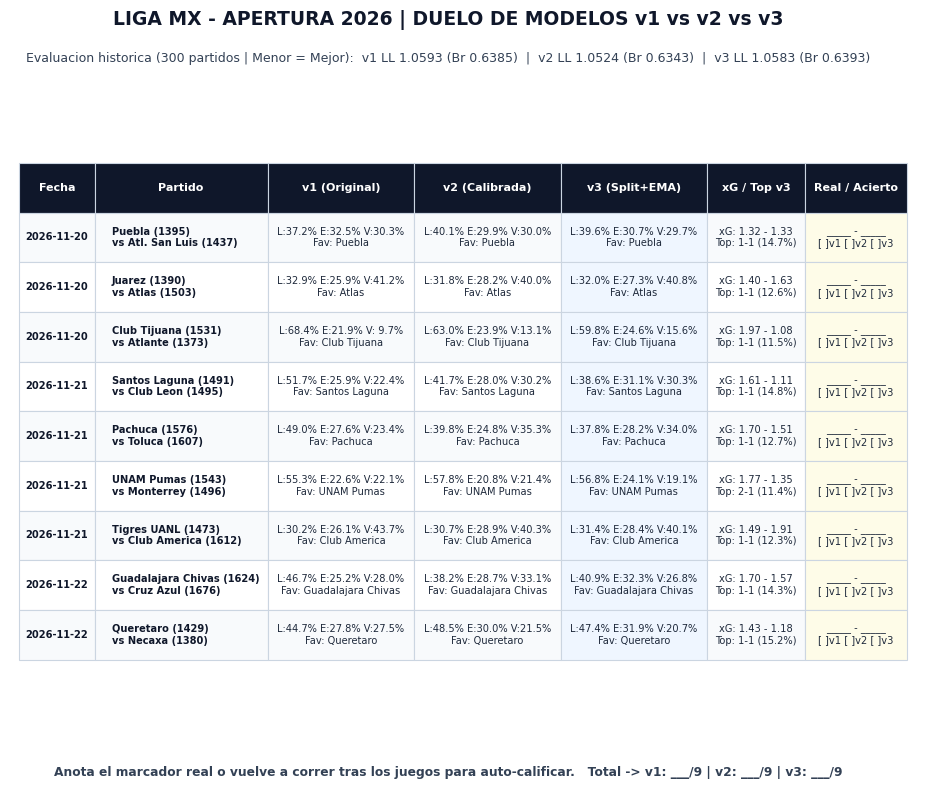

✅ PDF generado: predicciones_ligamx_v1_v2_v3.pdf


/kaggle/working/predicciones_ligamx_v1_v2_v3.pdf

In [2]:
import base64
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from IPython.display import display, HTML, FileLink

pdf_filename = "predicciones_ligamx_v1_v2_v3.pdf"
headers = [
    "Fecha",
    "Partido",
    "v1 (Original)",
    "v2 (Calibrada)",
    "v3 (Split+EMA)",
    "xG / Top v3",
    "Real / Acierto"
]

rows_pdf = []
jugados, ok1, ok2, ok3 = 0, 0, 0, 0

for r in resultados_j17:
    fav1 = etiqueta_fav(r["p1"], r["local"], r["visita"])
    fav2 = etiqueta_fav(r["p2"], r["local"], r["visita"])
    fav3 = etiqueta_fav(r["p3"], r["local"], r["visita"])

    col_f = r["fecha"]
    col_p = f"{r['local']} ({r['el']:.0f})\nvs {r['visita']} ({r['ev']:.0f})"
    col_1 = f"L:{r['p1'][0]*100:4.1f}% E:{r['p1'][1]*100:4.1f}% V:{r['p1'][2]*100:4.1f}%\nFav: {fav1}"
    col_2 = f"L:{r['p2'][0]*100:4.1f}% E:{r['p2'][1]*100:4.1f}% V:{r['p2'][2]*100:4.1f}%\nFav: {fav2}"
    col_3 = f"L:{r['p3'][0]*100:4.1f}% E:{r['p3'][1]*100:4.1f}% V:{r['p3'][2]*100:4.1f}%\nFav: {fav3}"
    col_x = f"xG: {r['lh3']:.2f} - {r['la3']:.2f}\nTop: {r['top'][0]}-{r['top'][1]} ({r['top_p']*100:.1f}%)"

    if r["real"] is not None:
        hg, ag, y_real = r["real"]
        jugados += 1
        c1 = int(np.argmax(r["p1"]) == y_real); ok1 += c1
        c2 = int(np.argmax(r["p2"]) == y_real); ok2 += c2
        c3 = int(np.argmax(r["p3"]) == y_real); ok3 += c3
        col_r = f"{hg} - {ag}\nv1:{'OK' if c1 else 'X'} v2:{'OK' if c2 else 'X'} v3:{'OK' if c3 else 'X'}"
    else:
        col_r = "_____ - _____\n[ ]v1 [ ]v2 [ ]v3"

    rows_pdf.append([col_f, col_p, col_1, col_2, col_3, col_x, col_r])

fig, ax = plt.subplots(figsize=(11.69, 8.27))
ax.axis("off")

fig.text(0.5, 0.945, "LIGA MX - APERTURA 2026 | DUELO DE MODELOS v1 vs v2 vs v3",
         ha="center", va="center", fontsize=13.5, fontweight="bold", color="#0F172A")
fig.text(0.5, 0.898,
         f"Evaluacion historica ({TEST_SIZE} partidos | Menor = Mejor):  "
         f"v1 LL {ll1:.4f} (Br {br1:.4f})  |  v2 LL {ll2:.4f} (Br {br2:.4f})  |  v3 LL {ll3:.4f} (Br {br3:.4f})",
         ha="center", va="center", fontsize=9.0, color="#334155")

table = ax.table(
    cellText=rows_pdf,
    colLabels=headers,
    colWidths=[0.085, 0.195, 0.165, 0.165, 0.165, 0.110, 0.115],
    cellLoc="center",
    bbox=[0.01, 0.08, 0.98, 0.78]
)
table.auto_set_font_size(False)
table.set_fontsize(7.1)

for (r, c), cell in table.get_celld().items():
    cell.set_edgecolor("#CBD5E1"); cell.set_linewidth(0.8)
    if r == 0:
        cell.set_facecolor("#0F172A")
        cell.set_text_props(color="white", fontweight="bold", fontsize=8.0)
    else:
        cell.set_facecolor("#EFF6FF" if c == 4 else ("#FEFCE8" if c == 6 else ("#F8FAFC" if r % 2 == 1 else "#FFFFFF")))
        cell.set_text_props(
            ha="left" if c == 1 else "center",
            fontweight="bold" if c in (0, 1) else "normal",
            color="#0F172A" if c in (0, 1) else "#1E293B"
        )

pie_txt = (
    f"Auto-calificacion en vivo ({jugados}/9 jugados):  v1: {ok1}/{jugados}  |  v2: {ok2}/{jugados}  |  v3: {ok3}/{jugados}"
    if jugados > 0 else
    "Anota el marcador real o vuelve a correr tras los juegos para auto-calificar.   Total -> v1: ___/9 | v2: ___/9 | v3: ___/9"
)
fig.text(0.5, 0.035, pie_txt, ha="center", va="center", fontsize=8.8, fontweight="bold", color="#334155")

with PdfPages(pdf_filename) as pdf:
    pdf.savefig(fig, dpi=200, bbox_inches="tight")
plt.show()

with open(pdf_filename, "rb") as f:
    b64 = base64.b64encode(f.read()).decode()

print(f"✅ PDF generado: {pdf_filename}")
display(FileLink(pdf_filename))
display(HTML(
    f'<a download="{pdf_filename}" href="data:application/pdf;base64,{b64}" '
    f'style="display:inline-block;margin-top:8px;padding:10px 16px;background:#0F172A;'
    f'color:#FFFFFF;text-decoration:none;border-radius:6px;font-weight:bold;">'
    f'Descargar PDF (Duelo v1 vs v2 vs v3)</a>'
))